Duplicate key in file PosixPath('/home/ning/miniconda3/envs/zd/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 272 ('font.sans-serif: DejaVu Sans, Bitstream Vera Sans, Computer Modern Sans Serif, Lucida Grande, Verdana, Geneva, Lucid, Arial, Helvetica, Avant Garde, sans-serif')
Duplicate key in file PosixPath('/home/ning/miniconda3/envs/zd/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 413 ('axes.unicode_minus: True  # use Unicode for the minus symbol rather than hyphen.  See')


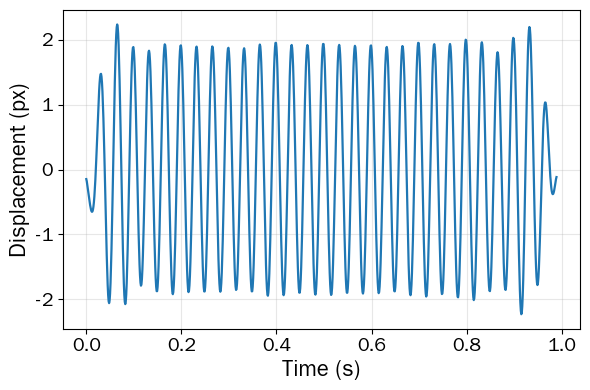

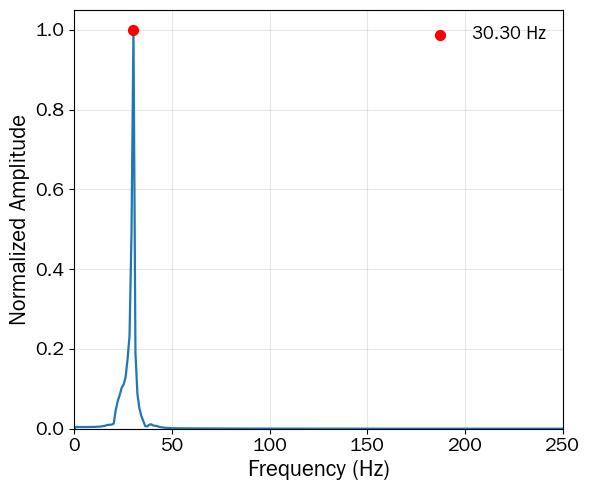

GPE: 频率=30.303030 Hz, 振幅(最大正峰值到0)=2.236414 px
时间—位移图：/home/ning/zd/results_222_30hz_requested/gpe_displacement_30hz.png
频谱图：/home/ning/zd/results_222_30hz_requested/gpe_spectrum_30hz.png


In [1]:
# GPE 完整重新实现
from pathlib import Path
import json
import h5py
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, detrend, filtfilt
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/30hz-20.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到data/30hz-20.hdf5")
data_path = root/"data/30hz-20.hdf5"
out_dir = root/"results_222_30hz_requested"
out_dir.mkdir(exist_ok=True)
roi = (100, 600, 420, 460)       # xmin, xmax, ymin, ymax
time_range = (0.0, 1.0)
frame_dt = 0.001
gabor_wavelength = 14.0

# 读取与ROI筛选（上下边界均包含）。
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]
x = raw["x"].astype(np.float32)
y = raw["y"].astype(np.float32)
t = raw["t"].astype(np.float64)*1e-6
xmin, xmax, ymin, ymax = roi
tmin, tmax = time_range
keep = ((x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax) &
        (t >= tmin) & (t <= tmax))
x, y, t = x[keep], y[keep], t[keep]
if len(t) == 0:
    raise ValueError("GPE的ROI和时间范围内没有事件")

# 1 ms事件帧：每帧少于50个事件时跳过，所有事件按1累加。
x0, x1 = int(x.min()), int(x.max())
y0, y1 = int(y.min()), int(y.max())
height, width = y1-y0+1, x1-x0+1
t0, t1 = float(t.min()), float(t.max())
frame_count = int((t1-t0)/frame_dt)
frames, frame_times = [], []
for k in range(frame_count):
    ta, tb = t0+k*frame_dt, t0+(k+1)*frame_dt
    mask = (t >= ta) & (t < tb)
    if int(np.sum(mask)) < 50:
        continue
    frame = np.zeros((height, width), dtype=np.float32)
    xi = (x[mask]-x0).astype(np.int32)
    yi = (y[mask]-y0).astype(np.int32)
    np.add.at(frame, (yi, xi), 1.0)
    frame = cv2.GaussianBlur(frame, (5, 5), 0)
    frames.append(frame)
    frame_times.append((ta+tb)/2)
frames = np.asarray(frames)
frame_times = np.asarray(frame_times)
if len(frames) < 20:
    raise ValueError("GPE有效事件帧不足")

# 31×31复Gabor响应：sigma=4、theta=pi/2、lambda=12、gamma=0.5。
real_kernel = cv2.getGaborKernel(
    (31, 31), 4.0, np.pi/2, gabor_wavelength, 0.5, 0)
imag_kernel = cv2.getGaborKernel(
    (31, 31), 4.0, np.pi/2, gabor_wavelength, 0.5, np.pi/2)
responses = np.empty(frames.shape, dtype=np.complex64)
for i, frame in enumerate(frames):
    responses[i] = (cv2.filter2D(frame, cv2.CV_32F, real_kernel) +
                    1j*cv2.filter2D(frame, cv2.CV_32F, imag_kernel))

# 逐像素沿时间展开相位，求相邻帧相位增量并按响应幅值加权。
phase_unwrapped = np.unwrap(np.angle(responses), axis=0)
response_amplitude = np.abs(responses)
phase_increment = np.diff(phase_unwrapped, axis=0)
phase_increment_signal = (
    np.sum(phase_increment*response_amplitude[:-1], axis=(1, 2)) /
    (np.sum(response_amplitude[:-1], axis=(1, 2))+1e-6)
)
phase_increment_signal -= np.mean(phase_increment_signal)
displacement_increment = phase_increment_signal*gabor_wavelength/(2*np.pi)

# 20–40 Hz四阶Butterworth带通，然后累加、去趋势和平滑。
sampling_rate = 1.0/float(np.mean(np.diff(frame_times)))
b, a = butter(4, [20/(0.5*sampling_rate), 40/(0.5*sampling_rate)],
              btype="band")
filtered_increment = filtfilt(b, a, displacement_increment)
displacement = gaussian_filter1d(
    detrend(np.cumsum(filtered_increment)), sigma=1.0)
times = frame_times[1:]

# 与当前版本绘图函数一致：缺失帧先插值到均匀时间轴，再减均值。
order = np.argsort(times)
times, displacement = times[order], displacement[order]
dt = float(np.median(np.diff(times)))
if not np.allclose(np.diff(times), dt, rtol=1e-5, atol=1e-10):
    uniform_times = np.arange(times[0], times[-1]+0.5*dt, dt)
    displacement = np.interp(uniform_times, times, displacement)
    times = uniform_times
times = times-times[0]
displacement = displacement-np.mean(displacement)
frequencies = np.fft.rfftfreq(len(displacement), d=dt)
magnitude = np.abs(np.fft.rfft(displacement))
spectrum = magnitude/(np.max(magnitude)+1e-12)
peak_index = int(np.argmax(spectrum[1:])+1)
frequency_hz = float(frequencies[peak_index])
amplitude_px = float(np.max(displacement))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, displacement, lw=1.6, color="tab:blue")
ax.set_xlabel("Time (s)", fontsize=16)
ax.set_ylabel("Displacement (px)", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3)
fig.tight_layout()
displacement_path = out_dir/"gpe_displacement_30hz.png"
fig.savefig(displacement_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(frequencies, spectrum, lw=1.6, color="tab:blue")
ax.scatter(frequency_hz, spectrum[peak_index], color="red", s=50,
           zorder=3, label=f"{frequency_hz:.2f} Hz")
ax.set_xlim(0, 250); ax.set_ylim(0, 1.05)
ax.set_xlabel("Frequency (Hz)", fontsize=16)
ax.set_ylabel("Normalized Amplitude", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=13)
fig.tight_layout()
spectrum_path = out_dir/"gpe_spectrum_30hz.png"
fig.savefig(spectrum_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

gpe_result = {
    "frequency_hz": frequency_hz,
    "amplitude_max_positive_px": amplitude_px,
    "minimum_px": float(np.min(displacement)),
    "maximum_px": float(np.max(displacement)),
    "samples": int(len(displacement)), "dt_s": dt,
    "settings": {"frame_dt_s": 0.002, "minimum_events": 50,
                 "gabor_size": 31, "gabor_sigma": 4.0,
                 "gabor_wavelength_px": 14.0,
                 "bandpass_hz": [20.0, 40.0], "smooth_sigma": 1.0},
}
np.savez(out_dir/"gpe_signal_30hz.npz", times=times,
         displacement=displacement, frequencies=frequencies,
         normalized_spectrum=spectrum)
(out_dir/"gpe_summary.json").write_text(
    json.dumps(gpe_result, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"GPE: 频率={frequency_hz:.6f} Hz, "
      f"振幅(最大正峰值到0)={amplitude_px:.6f} px")
print(f"时间—位移图：{displacement_path}")
print(f"频谱图：{spectrum_path}")


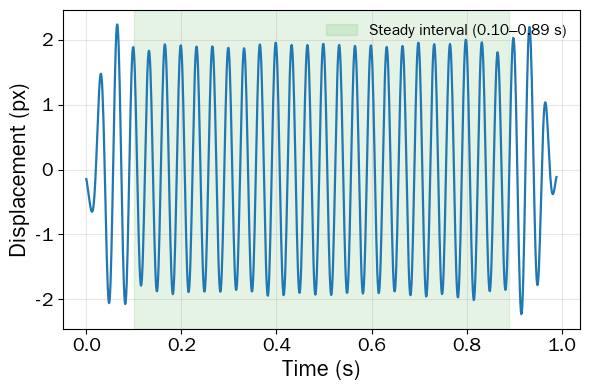

========== GPE稳态振幅（原GPE计算不变）==========
排除边界：开头和结尾各 0.100 s
稳态时间范围：0.100000–0.889000 s
稳态样本数：790
稳态最小位移：-2.000751 px
稳态最大位移：2.012749 px
稳态振幅（最大正峰值到0）：2.012749 px
稳态振幅（峰峰值/2）：2.006750 px
稳健振幅（1%–99%半范围）：1.936272 px
结果已保存：/home/ning/zd/results_222_30hz_requested/gpe_steady_amplitude_summary.json


In [2]:
# GPE稳态振幅报告：不重新计算、不修改前一代码块的GPE原理
# 直接使用前一代码块已经得到的 times 和 displacement。

import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

steady_edge_trim_s = 0.1  # 排除开头和结尾各0.1 s的滤波边界瞬态

gpe_times = np.asarray(times, dtype=float)
gpe_displacement = np.asarray(displacement, dtype=float)
if len(gpe_times) != len(gpe_displacement) or len(gpe_times) < 3:
    raise ValueError("请先运行前一个“GPE 完整重新实现”代码块")

steady_start_s = float(gpe_times[0] + steady_edge_trim_s)
steady_end_s = float(gpe_times[-1] - steady_edge_trim_s)
if steady_end_s <= steady_start_s:
    raise ValueError("位移序列太短，无法同时排除首尾边界")

steady_mask = ((gpe_times >= steady_start_s) &
               (gpe_times <= steady_end_s))
steady_times = gpe_times[steady_mask]
steady_displacement_raw = gpe_displacement[steady_mask]
if len(steady_displacement_raw) < 3:
    raise ValueError("稳态区间内有效样本不足")

# 仅对截取后的稳态序列重新定义零线，不改变原GPE位移计算。
steady_mean_px = float(np.mean(steady_displacement_raw))
steady_displacement = steady_displacement_raw - steady_mean_px
steady_minimum_px = float(np.min(steady_displacement))
steady_maximum_px = float(np.max(steady_displacement))

# 与原代码“最大正峰值到0”的定义保持一致。
steady_amplitude_max_positive_px = steady_maximum_px

# 同时给出常用半峰峰值，便于检查正负峰是否对称。
steady_peak_to_peak_px = steady_maximum_px - steady_minimum_px
steady_amplitude_half_ptp_px = steady_peak_to_peak_px / 2.0

# 1%–99%稳健半范围只作为抗离群点对照，不替代上面两个原始统计量。
steady_p01_px, steady_p99_px = np.percentile(
    steady_displacement, [1.0, 99.0])
steady_amplitude_robust_px = float(
    (steady_p99_px - steady_p01_px) / 2.0)

# 显示完整位移，并标出用于报告振幅的稳态区间。
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(gpe_times, gpe_displacement, lw=1.6, color="tab:blue")
ax.axvspan(steady_start_s, steady_end_s, color="tab:green", alpha=0.12,
           label=f"Steady interval ({steady_start_s:.2f}–{steady_end_s:.2f} s)")
ax.set_xlabel("Time (s)", fontsize=16)
ax.set_ylabel("Displacement (px)", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=11, loc="upper right")
fig.tight_layout()
display(fig)
plt.close(fig)

gpe_steady_result = {
    "source": "Existing GPE displacement from previous notebook cell",
    "gpe_calculation_changed": False,
    "edge_trim_each_side_s": steady_edge_trim_s,
    "steady_time_range_s": [steady_start_s, steady_end_s],
    "steady_samples": int(len(steady_displacement)),
    "steady_original_mean_px": steady_mean_px,
    "steady_minimum_px": steady_minimum_px,
    "steady_maximum_px": steady_maximum_px,
    "steady_peak_to_peak_px": steady_peak_to_peak_px,
    "steady_amplitude_max_positive_px": steady_amplitude_max_positive_px,
    "steady_amplitude_half_peak_to_peak_px": steady_amplitude_half_ptp_px,
    "steady_amplitude_robust_p01_p99_px": steady_amplitude_robust_px,
}

steady_summary_path = out_dir / "gpe_steady_amplitude_summary.json"
steady_summary_path.write_text(
    json.dumps(gpe_steady_result, ensure_ascii=False, indent=2),
    encoding="utf-8")

print("========== GPE稳态振幅（原GPE计算不变）==========")
print(f"排除边界：开头和结尾各 {steady_edge_trim_s:.3f} s")
print(f"稳态时间范围：{steady_start_s:.6f}–{steady_end_s:.6f} s")
print(f"稳态样本数：{len(steady_displacement)}")
print(f"稳态最小位移：{steady_minimum_px:.6f} px")
print(f"稳态最大位移：{steady_maximum_px:.6f} px")
print(f"稳态振幅（最大正峰值到0）：{steady_amplitude_max_positive_px:.6f} px")
print(f"稳态振幅（峰峰值/2）：{steady_amplitude_half_ptp_px:.6f} px")
print(f"稳健振幅（1%–99%半范围）：{steady_amplitude_robust_px:.6f} px")
print(f"结果已保存：{steady_summary_path}")


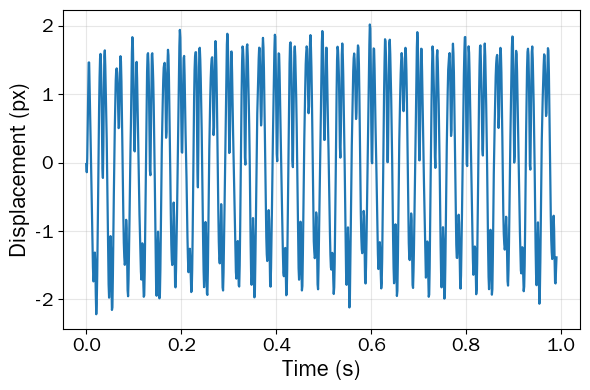

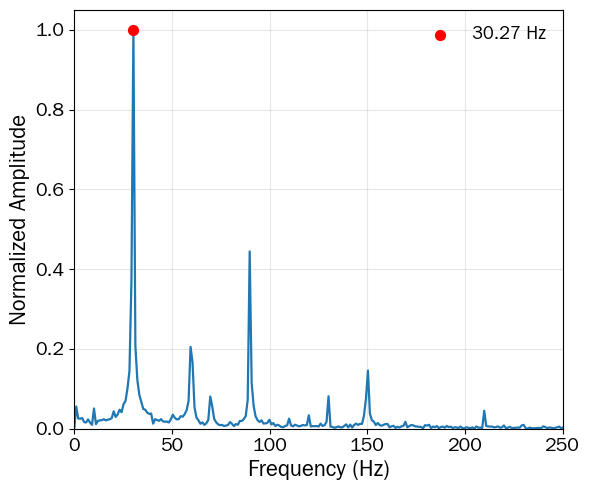

ECT: 频率=30.272452 Hz, 振幅(最大正峰值到0)=2.020129 px
时间—位移图：/home/ning/zd/results_222_30hz_requested/ect_displacement_30hz.png
频谱图：/home/ning/zd/results_222_30hz_requested/ect_spectrum_30hz.png


In [3]:
# ECT：完整重新实现
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/30hz-20.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到data/30hz-20.hdf5")
data_path = root/"data/30hz-20.hdf5"
out_dir = root/"results_222_30hz_requested"
out_dir.mkdir(exist_ok=True)
roi = (100, 600, 420, 460)
time_range = (0.0, 1.0)
window_dt = 0.001
minimum_events = 30

# 读取事件，时间戳由微秒转换为秒，并按ROI和时间范围筛选。
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]
x = raw["x"].astype(float)
y = raw["y"].astype(float)
t = raw["t"].astype(float)*1e-6
xmin, xmax, ymin, ymax = roi
tmin, tmax = time_range
keep = ((x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax) &
        (t >= tmin) & (t <= tmax))
t, y = t[keep], y[keep]
if len(t) == 0:
    raise ValueError("ECT的ROI和时间范围内没有事件")

# 每1 ms直接计算事件纵坐标平均值；不足30个事件的窗口跳过。
t0, t1 = float(t.min()), float(t.max())
bin_count = int((t1-t0)//window_dt)
centers, times = [], []
for i in range(bin_count):
    ta, tb = t0+i*window_dt, t0+(i+1)*window_dt
    mask = (t >= ta) & (t < tb)
    if int(np.sum(mask)) < minimum_events:
        continue
    centers.append(float(np.mean(y[mask])))
    times.append((ta+tb)/2)
centers = np.asarray(centers)
times = np.asarray(times)
if len(centers) < 3:
    raise ValueError("ECT有效质心样本不足")
centers = gaussian_filter1d(centers-np.mean(centers), sigma=1.0)

# 缺失窗口线性插值到均匀时间轴，然后再次严格均值归零。
dt = float(np.median(np.diff(times)))
if not np.allclose(np.diff(times), dt, rtol=1e-5, atol=1e-10):
    uniform_times = np.arange(times[0], times[-1]+0.5*dt, dt)
    centers = np.interp(uniform_times, times, centers)
    times = uniform_times
times = times-times[0]
displacement = centers-np.mean(centers)
frequencies = np.fft.rfftfreq(len(displacement), d=dt)
magnitude = np.abs(np.fft.rfft(displacement))
spectrum = magnitude/(np.max(magnitude)+1e-12)
peak_index = int(np.argmax(spectrum[1:])+1)
frequency_hz = float(frequencies[peak_index])
amplitude_px = float(np.max(displacement))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, displacement, lw=1.6, color="tab:blue")
ax.set_xlabel("Time (s)", fontsize=16)
ax.set_ylabel("Displacement (px)", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3)
fig.tight_layout()
displacement_path = out_dir/"ect_displacement_30hz.png"
fig.savefig(displacement_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(frequencies, spectrum, lw=1.6, color="tab:blue")
ax.scatter(frequency_hz, spectrum[peak_index], color="red", s=50,
           zorder=3, label=f"{frequency_hz:.2f} Hz")
ax.set_xlim(0, 250); ax.set_ylim(0, 1.05)
ax.set_xlabel("Frequency (Hz)", fontsize=16)
ax.set_ylabel("Normalized Amplitude", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=13)
fig.tight_layout()
spectrum_path = out_dir/"ect_spectrum_30hz.png"
fig.savefig(spectrum_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

ect_result = {
    "frequency_hz": frequency_hz,
    "amplitude_max_positive_px": amplitude_px,
    "minimum_px": float(np.min(displacement)),
    "maximum_px": float(np.max(displacement)),
    "samples": int(len(displacement)), "dt_s": dt,
    "settings": {"window_dt_s": 0.001,
                 "minimum_events_per_window": 30,
                 "smooth_sigma": 1.0},
}
np.savez(out_dir/"ect_signal_30hz.npz", times=times,
         displacement=displacement, frequencies=frequencies,
         normalized_spectrum=spectrum)
(out_dir/"ect_summary.json").write_text(
    json.dumps(ect_result, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"ECT: 频率={frequency_hz:.6f} Hz, "
      f"振幅(最大正峰值到0)={amplitude_px:.6f} px")
print(f"时间—位移图：{displacement_path}")
print(f"频谱图：{spectrum_path}")


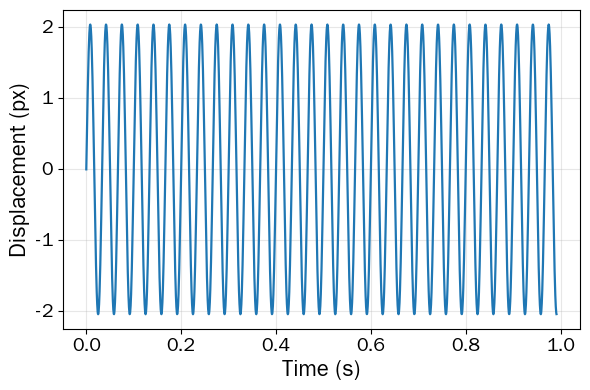

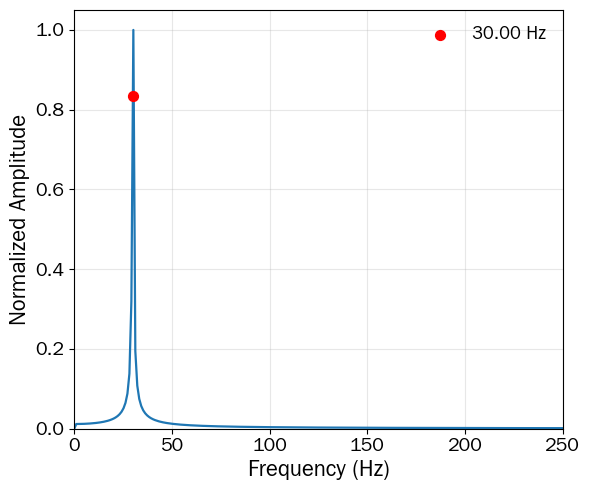

3DFIT: 连续拟合频率=29.999791 Hz, 位移FFT峰值=30.243887 Hz, 模型法向振幅=2.041628 px
时间—位移图：/home/ning/zd/results_222_30hz_requested/3dfit_displacement_30hz.png
频谱图：/home/ning/zd/results_222_30hz_requested/3dfit_spectrum_30hz.png


In [4]:
# 3DFIT：完整独立实现
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.signal import czt, find_peaks
from IPython.display import display
try:
    import finufft
except ImportError:
    finufft = None

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/"data/30hz-20.hdf5").exists()), None)
if root is None:
    raise FileNotFoundError("找不到data/30hz-20.hdf5")
data_path = root/"data/30hz-20.hdf5"
out_dir = root/"results_222_30hz_requested"
out_dir.mkdir(exist_ok=True)
roi = (100, 600, 420, 460)
time_range = (0.0, 1.0)

# 读取事件并按时空ROI筛选。
with h5py.File(data_path, "r") as handle:
    raw = handle["CD/events"][:]
all_x = raw["x"].astype(np.float64)
all_y = raw["y"].astype(np.float64)
all_t = raw["t"].astype(np.float64)*1e-6
xmin, xmax, ymin, ymax = roi
tmin, tmax = time_range
keep = ((all_x >= xmin) & (all_x <= xmax) &
        (all_y >= ymin) & (all_y <= ymax) &
        (all_t >= tmin) & (all_t <= tmax))
event_data = {"x": all_x[keep], "y": all_y[keep], "t": all_t[keep]}
if len(event_data["t"]) < 100:
    raise ValueError("3DFIT的ROI内有效事件少于100个")

# 按横坐标以800 px分组，每组至少100个事件。
group_size, minimum_events = 800, 100
group_bounds = np.arange(event_data["x"].min(),
                         event_data["x"].max()+group_size, group_size)
groups = []
for group_id in range(len(group_bounds)-1):
    x0, x1 = group_bounds[group_id], group_bounds[group_id+1]
    mask = (event_data["x"] >= x0) & (event_data["x"] < x1)
    if int(np.sum(mask)) < minimum_events:
        continue
    groups.append({"id": group_id, "x_range": (x0, x1),
                   "x": event_data["x"][mask],
                   "y": event_data["y"][mask],
                   "t": event_data["t"][mask]})

fitted_groups = []
for group in groups:
    raw_x, raw_y, raw_t = group["x"], group["y"], group["t"]
    centered_x = raw_x-np.mean(raw_x)
    centered_y = raw_y-np.mean(raw_y)
    elapsed_t = raw_t-np.min(raw_t)

    covariance = np.cov(np.stack((centered_x, centered_y)))
    _, eigenvectors = np.linalg.eigh(covariance)
    pca_normal = eigenvectors[:, 0]
    weights = pca_normal[0]*centered_x+pca_normal[1]*centered_y
    weights -= np.mean(weights)
    weight_scale = float(np.std(weights))
    if not np.isfinite(weight_scale) or weight_scale <= 1e-12:
        continue
    nufft_weights = np.ascontiguousarray(
        (weights/weight_scale).astype(np.complex128))

    # 1–500 Hz、0.1 Hz间隔的Type-3 NUFFT。
    candidate_grid = np.arange(1.0, 500.0+0.05, 0.1, dtype=np.float64)
    if finufft is not None:
        transform = finufft.nufft1d3(
            np.ascontiguousarray(elapsed_t), nufft_weights,
            np.ascontiguousarray(2*np.pi*candidate_grid),
            isign=-1, eps=1e-7)
        transform_backend = "finufft_type3"
    else:
        # 数据时间戳为整数微秒；此后备路径在原生微秒网格上计算同一复指数和。
        timestamp_step = 1e-6
        sample_index = np.rint(elapsed_t/timestamp_step).astype(np.int64)
        sample_count = int(sample_index.max())+1
        gridded = (
            np.bincount(sample_index, weights=np.real(nufft_weights),
                        minlength=sample_count) +
            1j*np.bincount(sample_index, weights=np.imag(nufft_weights),
                           minlength=sample_count))
        transform = czt(
            gridded, m=len(candidate_grid),
            w=np.exp(-2j*np.pi*0.1*timestamp_step),
            a=np.exp(2j*np.pi*1.0*timestamp_step))
        transform_backend = "scipy_czt_microsecond_grid"
    nufft_power = np.abs(transform)

    # 局部峰按至少max(0.5,1/T) Hz分隔；强峰阈值为最高峰的50%。
    duration = float(np.ptp(elapsed_t))
    peak_separation_hz = max(0.5, 1.0/duration) if duration > 0 else 0.5
    peak_distance = max(1, int(round(peak_separation_hz/0.1)))
    peak_indices, _ = find_peaks(nufft_power, distance=peak_distance)
    if len(peak_indices) == 0:
        peak_indices = np.array([int(np.argmax(nufft_power))])
    ordered = peak_indices[np.argsort(nufft_power[peak_indices])[::-1]]
    strongest = float(nufft_power[ordered[0]])
    strong = [int(i) for i in ordered if nufft_power[i] >= 0.5*strongest]
    primary_frequency = float(np.min(candidate_grid[strong]))

    frequency_candidates = [primary_frequency]
    for index in ordered[:8]:
        peak_frequency = float(candidate_grid[index])
        frequency_candidates.extend(
            [peak_frequency, peak_frequency/2.0, peak_frequency/3.0])
    unique_candidates = []
    for frequency in frequency_candidates:
        if (1.0 <= frequency <= 500.0 and
                not any(abs(frequency-old) < 0.05
                        for old in unique_candidates)):
            unique_candidates.append(float(frequency))

    accepted = None
    attempted = []
    for initial_frequency in unique_candidates:
        spectrum_index = int(np.argmin(np.abs(candidate_grid-initial_frequency)))
        coefficient = transform[spectrum_index]
        initial_amplitude = (
            2.0*abs(coefficient)/len(elapsed_t)*weight_scale)
        initial_phase = float(
            (np.angle(coefficient)-0.5*np.pi+np.pi)%(2*np.pi)-np.pi)
        initial_parameters = [float(pca_normal[0]), float(pca_normal[1]),
                              max(float(initial_amplitude), 1e-6),
                              initial_frequency, initial_phase, 0.1, 0.0]

        def objective(parameters):
            A, B, C, frequency, phase, decay, offset = parameters
            vibration = (C*np.exp(-decay*elapsed_t)*
                         np.sin(2*np.pi*frequency*elapsed_t+phase))
            residual = A*centered_x+B*centered_y+vibration+offset
            normal_penalty = 1e6*(np.hypot(A, B)-1.0)**2
            return np.mean(residual**2)+normal_penalty

        half_window = max(0.5, 0.02*initial_frequency)
        frequency_bounds = (max(1.0, initial_frequency-half_window),
                            min(500.0, initial_frequency+half_window))
        optimization = minimize(
            objective, initial_parameters, method="L-BFGS-B",
            bounds=[(-1, 1), (-1, 1), (0, None), frequency_bounds,
                    (-np.pi, np.pi), (0, 10), (None, None)])
        attempted.append(initial_frequency)
        if not optimization.success or not np.all(np.isfinite(optimization.x)):
            continue

        parameters = optimization.x.copy()
        A, B, C, frequency, phase, decay, offset = parameters
        normal_norm = float(np.hypot(A, B))
        if normal_norm <= 1e-9:
            continue
        vibration = (C*np.exp(-decay*elapsed_t)*
                     np.sin(2*np.pi*frequency*elapsed_t+phase))
        model_residual = A*centered_x+B*centered_y+vibration+offset
        static_residual = A*centered_x+B*centered_y+offset
        model_mse = float(np.mean(model_residual**2))
        static_mse = float(np.mean(static_residual**2))
        relative_improvement = ((static_mse-model_mse)/static_mse
                                if static_mse > 1e-12 else 0.0)
        amplitude = float(abs(C)/normal_norm)
        if (amplitude < 1e-3 or relative_improvement < 1e-6 or
                frequency <= 1.05 or frequency >= 499.95):
            continue
        parameters[[0, 1, 2, 6]] /= normal_norm
        accepted = {
            "parameters": parameters,
            "nufft_primary_frequency": primary_frequency,
            "fit_initial_frequency": initial_frequency,
            "relative_improvement": relative_improvement,
            "transform_backend": transform_backend,
        }
        break
    if accepted is not None:
        fitted_groups.append(accepted)

if not fitted_groups:
    raise RuntimeError("30 Hz GitHub NUFFT 3DFIT拟合失败")

# 多分组结果取中位数；振幅为|C|/sqrt(A²+B²)。
frequency_hz = float(np.median(
    [group["parameters"][3] for group in fitted_groups]))
amplitude_px = float(np.median([
    abs(group["parameters"][2]) /
    np.hypot(group["parameters"][0], group["parameters"][1])
    for group in fitted_groups]))
decay = float(np.median(
    [group["parameters"][5] for group in fitted_groups]))

# 按当前GitHub estimator逻辑重建模型位移。
duration = float(np.ptp(event_data["t"]))
sample_count = max(2, int(np.ceil(duration*max(2000, 4*frequency_hz))))
times = np.arange(sample_count)*duration/sample_count
displacement = (amplitude_px*np.exp(-decay*times)*
                np.sin(2*np.pi*frequency_hz*times))
displacement -= np.mean(displacement)
dt = duration/sample_count
frequencies = np.fft.rfftfreq(sample_count, d=dt)
magnitude = np.abs(np.fft.rfft(displacement))
spectrum = magnitude/(np.max(magnitude)+1e-12)
fft_peak_index = int(np.argmax(spectrum[1:])+1)
fft_peak_hz = float(frequencies[fft_peak_index])
marker_height = float(np.interp(frequency_hz, frequencies, spectrum))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, displacement, lw=1.6, color="tab:blue")
ax.set_xlabel("Time (s)", fontsize=16)
ax.set_ylabel("Displacement (px)", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3)
fig.tight_layout()
displacement_path = out_dir/"3dfit_displacement_30hz.png"
fig.savefig(displacement_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(frequencies, spectrum, lw=1.6, color="tab:blue")
ax.scatter(frequency_hz, marker_height, color="red", s=50, zorder=3,
           label=f"{frequency_hz:.2f} Hz")
ax.set_xlim(0, 250); ax.set_ylim(0, 1.05)
ax.set_xlabel("Frequency (Hz)", fontsize=16)
ax.set_ylabel("Normalized Amplitude", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=13)
fig.tight_layout()
spectrum_path = out_dir/"3dfit_spectrum_30hz.png"
fig.savefig(spectrum_path, dpi=300, bbox_inches="tight")
display(fig); plt.close(fig)

fit_result = {
    "frequency_hz": frequency_hz,
    "displacement_fft_peak_hz": fft_peak_hz,
    "model_amplitude_px": amplitude_px,
    "amplitude_max_positive_px": float(np.max(displacement)),
    "minimum_px": float(np.min(displacement)),
    "maximum_px": float(np.max(displacement)),
    "fitted_group_count": len(fitted_groups),
    "nufft_initial_frequencies": [
        group["nufft_primary_frequency"] for group in fitted_groups],
    "fit_initial_frequencies": [
        group["fit_initial_frequency"] for group in fitted_groups],
    "relative_improvements": [
        group["relative_improvement"] for group in fitted_groups],
    "nufft_transform_backends": [
        group["transform_backend"] for group in fitted_groups],
}
np.savez(out_dir/"3dfit_signal_30hz.npz", times=times,
         displacement=displacement, frequencies=frequencies,
         normalized_spectrum=spectrum)
(out_dir/"three_dfit_summary.json").write_text(
    json.dumps(fit_result, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"3DFIT: 连续拟合频率={frequency_hz:.6f} Hz, "
      f"位移FFT峰值={fft_peak_hz:.6f} Hz, "
      f"模型法向振幅={amplitude_px:.6f} px")
print(f"时间—位移图：{displacement_path}")
print(f"频谱图：{spectrum_path}")


## 三种方法的均值归零位移频谱和时间位移曲线（钢尺数据）

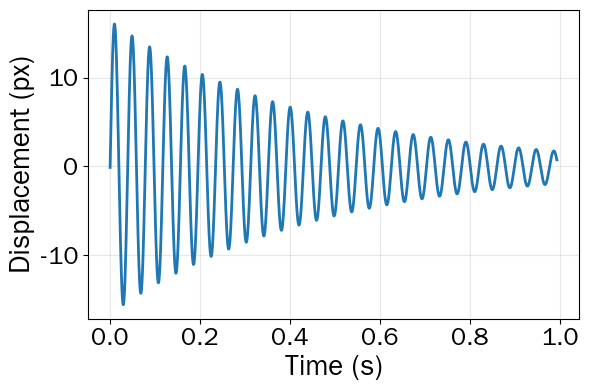

3DFIT: 频率=25.615154 Hz, 最小位移=-15.582217 px, 最大位移=16.041630 px, 单侧峰值振幅=16.041630 px
  图片已保存：3dfit_inline_displacement_zdbiaochi.png


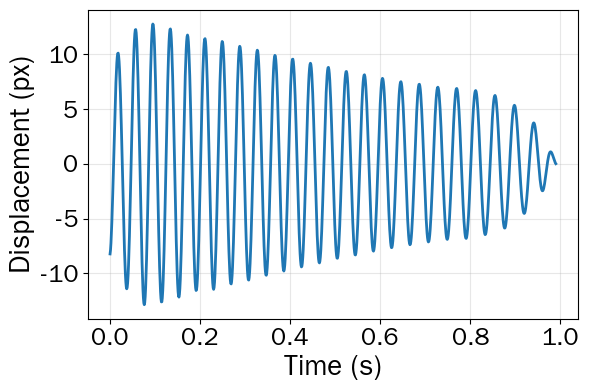

GPE: 频率=25.227043 Hz, 最小位移=-12.863890 px, 最大位移=12.765709 px, 单侧峰值振幅=12.765709 px
  图片已保存：gpe_inline_displacement_zdbiaochi.png


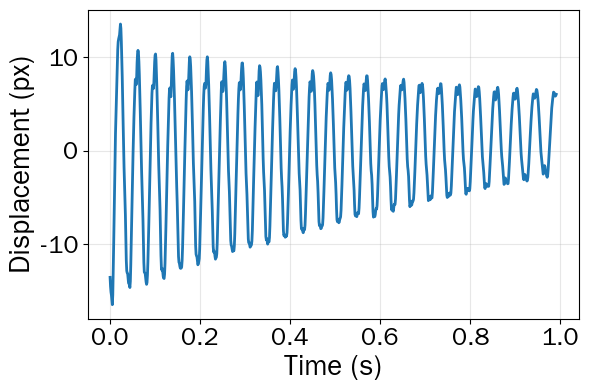

ECT: 频率=25.201613 Hz, 最小位移=-16.428737 px, 最大位移=13.521881 px, 单侧峰值振幅=13.521881 px
  图片已保存：ect_inline_displacement_zdbiaochi.png


516

In [5]:
# 三种方法的独立实现：不调用 6.2 或 github 目录中的项目函数
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import minimize
from scipy.signal import butter, filtfilt, detrend, czt, find_peaks
from IPython.display import display

try:
    import finufft
except ImportError:
    finufft = None

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/zdbiaochi.hdf5").exists()), None)
if ROOT is None:
    raise FileNotFoundError("找不到 data/zdbiaochi.hdf5")

DATA_PATH = ROOT / "data/zdbiaochi.hdf5"
OUT_DIR = ROOT / "results_gangchi_inline"
OUT_DIR.mkdir(exist_ok=True)
ROI = (600, 700, 400, 600)       # xmin, xmax, ymin, ymax
TIME_RANGE = (0.0, 1.0)

# ---------- 读取并截取同一批原始事件 ----------
with h5py.File(DATA_PATH, "r") as handle:
    raw = handle["CD/events"][:]
x_all = raw["x"].astype(np.float64)
y_all = raw["y"].astype(np.float64)
t_all = raw["t"].astype(np.float64) * 1e-6
p_all = raw["p"].astype(np.float64)
del raw
xmin, xmax, ymin, ymax = ROI
tmin, tmax = TIME_RANGE
mask = ((x_all >= xmin) & (x_all <= xmax) &
        (y_all >= ymin) & (y_all <= ymax) &
        (t_all >= tmin) & (t_all <= tmax))
events = {"x": x_all[mask], "y": y_all[mask],
          "t": t_all[mask], "p": p_all[mask]}
del x_all, y_all, t_all, p_all, mask
if len(events["t"]) < 100:
    raise RuntimeError("ROI内事件数量不足")

def uniform_and_center(times, displacement):
    times = np.asarray(times, dtype=np.float64)
    displacement = np.asarray(displacement, dtype=np.float64)
    order = np.argsort(times)
    times, displacement = times[order], displacement[order]
    dt = float(np.median(np.diff(times)))
    if not np.allclose(np.diff(times), dt, rtol=1e-5, atol=1e-10):
        uniform_times = np.arange(times[0], times[-1] + 0.5 * dt, dt)
        displacement = np.interp(uniform_times, times, displacement)
        times = uniform_times
    return times - times[0], displacement - np.mean(displacement)

def fft_peak(times, displacement):
    dt = float(np.mean(np.diff(times)))
    frequencies = np.fft.rfftfreq(len(displacement), d=dt)
    magnitude = np.abs(np.fft.rfft(displacement - np.mean(displacement)))
    peak_index = int(np.argmax(magnitude[1:]) + 1)
    return float(frequencies[peak_index])

# =========================================================
# 方法一：ECT（1 ms质心、至少30个事件、sigma=1.0）
# =========================================================
dt_ect = 0.001
t0, t1 = events["t"].min(), events["t"].max()
n_bins = int((t1 - t0) // dt_ect)
ect_time_list, ect_center_list = [], []
for i in range(n_bins):
    ta, tb = t0 + i * dt_ect, t0 + (i + 1) * dt_ect
    in_bin = (events["t"] >= ta) & (events["t"] < tb)
    if np.count_nonzero(in_bin) >= 30:
        ect_time_list.append((ta + tb) / 2.0)
        ect_center_list.append(np.mean(events["y"][in_bin]))
ect_times_raw = np.asarray(ect_time_list)
ect_signal_raw = gaussian_filter1d(
    np.asarray(ect_center_list) - np.mean(ect_center_list), sigma=1.0)
ect_times, ect_signal = uniform_and_center(ect_times_raw, ect_signal_raw)
ect_frequency = fft_peak(ect_times, ect_signal)

# =========================================================
# 方法二：GPE（1 ms事件帧、复Gabor、20–40 Hz带通）
# =========================================================
frame_dt = 0.001
gx0, gx1 = int(events["x"].min()), int(events["x"].max())
gy0, gy1 = int(events["y"].min()), int(events["y"].max())
width, height = gx1 - gx0 + 1, gy1 - gy0 + 1
n_frames = int((t1 - t0) / frame_dt)
gpe_frames, gpe_frame_times = [], []
for k in range(n_frames):
    ta, tb = t0 + k * frame_dt, t0 + (k + 1) * frame_dt
    in_frame = (events["t"] >= ta) & (events["t"] < tb)
    if np.count_nonzero(in_frame) < 50:
        continue
    frame = np.zeros((height, width), dtype=np.float32)
    xs = (events["x"][in_frame] - gx0).astype(np.int32)
    ys = (events["y"][in_frame] - gy0).astype(np.int32)
    np.add.at(frame, (ys, xs), 1.0)
    gpe_frames.append(cv2.GaussianBlur(frame, (5, 5), 0))
    gpe_frame_times.append((ta + tb) / 2.0)
gpe_frames = np.asarray(gpe_frames)
gpe_frame_times = np.asarray(gpe_frame_times)

real_kernel = cv2.getGaborKernel(
    (31, 31), 4.0, np.pi / 2, 12.0, 0.5, 0, ktype=cv2.CV_32F)
imag_kernel = cv2.getGaborKernel(
    (31, 31), 4.0, np.pi / 2, 12.0, 0.5, np.pi / 2, ktype=cv2.CV_32F)
complex_responses = []
for frame in gpe_frames:
    real_response = cv2.filter2D(frame, cv2.CV_32F, real_kernel)
    imag_response = cv2.filter2D(frame, cv2.CV_32F, imag_kernel)
    complex_responses.append(real_response + 1j * imag_response)
complex_responses = np.asarray(complex_responses)
phase = np.unwrap(np.angle(complex_responses), axis=0)
response_amplitude = np.abs(complex_responses)
phase_increment = np.diff(phase, axis=0)
weighted_increment = (
    np.sum(phase_increment * response_amplitude[:-1], axis=(1, 2)) /
    (np.sum(response_amplitude[:-1], axis=(1, 2)) + 1e-6)
)
weighted_increment -= np.mean(weighted_increment)
pixel_increment = weighted_increment * 12.0 / (2.0 * np.pi)
sampling_rate = 1.0 / np.mean(np.diff(gpe_frame_times))
b, a = butter(4, [20.0 / (0.5 * sampling_rate),
                  40.0 / (0.5 * sampling_rate)], btype="band")
pixel_increment = filtfilt(b, a, pixel_increment)
gpe_signal_raw = gaussian_filter1d(detrend(np.cumsum(pixel_increment)), sigma=1.0)
gpe_times_raw = gpe_frame_times[1:]
gpe_times, gpe_signal = uniform_and_center(gpe_times_raw, gpe_signal_raw)
gpe_frequency = fft_peak(gpe_times, gpe_signal)
del gpe_frames, complex_responses, phase, response_amplitude, phase_increment

# =========================================================
# 方法三：3DFIT（PCA投影的Type-3 NUFFT初始化+隐式曲面拟合）
# 完整算法写在本单元内，不导入 github/methods/three_dfit。
# =========================================================
def nonuniform_transform(times, weights, frequencies):
    angular_frequencies = np.ascontiguousarray(2.0 * np.pi * frequencies)
    if finufft is not None:
        transform = finufft.nufft1d3(
            np.ascontiguousarray(times, dtype=np.float64),
            np.ascontiguousarray(weights, dtype=np.complex128),
            angular_frequencies, isign=-1, eps=1e-7)
        return transform, "finufft_type3"
    timestamp_step = 1e-6
    sample_index = np.rint(times / timestamp_step).astype(np.int64)
    sample_count = int(sample_index.max()) + 1
    gridded = (np.bincount(sample_index, weights=np.real(weights),
                           minlength=sample_count) +
               1j * np.bincount(sample_index, weights=np.imag(weights),
                                 minlength=sample_count))
    frequency_step = float(frequencies[1] - frequencies[0])
    transform = czt(
        gridded, m=len(frequencies),
        w=np.exp(-2j * np.pi * frequency_step * timestamp_step),
        a=np.exp(2j * np.pi * float(frequencies[0]) * timestamp_step))
    return transform, "scipy_czt_microsecond_grid"

def nufft_initialization(group_data):
    x, y, t = group_data["x"], group_data["y"], group_data["t"]
    xc, yc = x - np.mean(x), y - np.mean(y)
    covariance = np.cov(np.stack((xc, yc)))
    _, eigenvectors = np.linalg.eigh(covariance)
    normal = eigenvectors[:, 0]
    weights = normal[0] * xc + normal[1] * yc
    weights -= np.mean(weights)
    weight_scale = float(np.std(weights))
    weights = np.ascontiguousarray((weights / weight_scale).astype(np.complex128))
    elapsed = np.ascontiguousarray(t - np.min(t), dtype=np.float64)
    frequencies = np.arange(1.0, 500.0 + 0.05, 0.1)
    transform, backend = nonuniform_transform(elapsed, weights, frequencies)
    power = np.abs(transform)
    duration = float(np.ptp(elapsed))
    peak_distance = max(1, int(round(max(0.5, 1.0 / duration) / 0.1)))
    peak_indices, _ = find_peaks(power, distance=peak_distance)
    if len(peak_indices) == 0:
        peak_indices = np.array([int(np.argmax(power))])
    ordered = peak_indices[np.argsort(power[peak_indices])[::-1]]
    strongest = float(power[ordered[0]])
    strong = [int(i) for i in ordered if power[i] >= 0.5 * strongest]
    primary = float(np.min(frequencies[strong]))
    candidates = [primary]
    for index in ordered[:8]:
        f = float(frequencies[index])
        candidates.extend((f, f / 2.0, f / 3.0))
    unique = []
    for f in candidates:
        if 1.0 <= f <= 500.0 and not any(abs(f - old) < 0.05 for old in unique):
            unique.append(float(f))
    return {"frequency": primary, "candidates": unique, "normal": normal,
            "weight_scale": weight_scale, "frequencies": frequencies,
            "transform": transform, "backend": backend}

def fit_one_group(group_data):
    x_raw, y_raw, t_raw = group_data["x"], group_data["y"], group_data["t"]
    x, y, t = x_raw - np.mean(x_raw), y_raw - np.mean(y_raw), t_raw - np.min(t_raw)
    init = nufft_initialization(group_data)
    for initial_frequency in init["candidates"]:
        spectrum_index = int(np.argmin(np.abs(init["frequencies"] - initial_frequency)))
        coefficient = init["transform"][spectrum_index]
        initial_amplitude = max(
            2.0 * abs(coefficient) / len(t) * init["weight_scale"], 1e-6)
        initial_phase = float(
            (np.angle(coefficient) - 0.5 * np.pi + np.pi) % (2 * np.pi) - np.pi)
        p0 = [float(init["normal"][0]), float(init["normal"][1]),
              initial_amplitude, initial_frequency, initial_phase, 0.1, 0.0]

        def objective(parameters):
            A, B, C, frequency, phi, decay, D = parameters
            vibration = C * np.exp(-decay * t) * np.sin(
                2.0 * np.pi * frequency * t + phi)
            residual = A * x + B * y + vibration + D
            return np.mean(residual ** 2) + 1e6 * (np.hypot(A, B) - 1.0) ** 2

        half_window = max(0.5, 0.02 * initial_frequency)
        result = minimize(
            objective, p0, method="L-BFGS-B",
            bounds=[(-1, 1), (-1, 1), (0, None),
                    (max(1.0, initial_frequency - half_window),
                     min(500.0, initial_frequency + half_window)),
                    (-np.pi, np.pi), (0, 10), (None, None)])
        if not result.success or not np.all(np.isfinite(result.x)):
            continue
        A, B, C, frequency, phi, decay, D = result.x
        normal_norm = float(np.hypot(A, B))
        if normal_norm <= 1e-9:
            continue
        model_residual = (A * x + B * y +
                          C * np.exp(-decay * t) * np.sin(2*np.pi*frequency*t + phi) + D)
        static_residual = A * x + B * y + D
        model_mse = float(np.mean(model_residual ** 2))
        static_mse = float(np.mean(static_residual ** 2))
        improvement = ((static_mse - model_mse) / static_mse
                       if static_mse > 1e-12 else 0.0)
        amplitude = float(abs(C) / normal_norm)
        if amplitude < 1e-3 or improvement < 1e-6 or frequency <= 1.05 or frequency >= 499.95:
            continue
        parameters = result.x.copy()
        parameters[[0, 1, 2, 6]] /= normal_norm
        return {"params": parameters, "improvement": improvement,
                "nufft_frequency": init["frequency"], "backend": init["backend"]}
    return None

# 与github版本一致：按x方向分组；当前ROI宽度小于800 px，形成一个有效组。
group_size, min_events = 800, 100
bounds = np.arange(events["x"].min(), events["x"].max() + group_size, group_size)
fitted_groups = []
for group_id in range(len(bounds) - 1):
    group_mask = ((events["x"] >= bounds[group_id]) &
                  (events["x"] < bounds[group_id + 1]))
    if np.count_nonzero(group_mask) < min_events:
        continue
    fitted = fit_one_group({key: value[group_mask] for key, value in events.items()})
    if fitted is not None:
        fitted_groups.append(fitted)
if not fitted_groups:
    raise RuntimeError("3DFIT连续隐式曲面拟合失败")

fit_frequency = float(np.median([g["params"][3] for g in fitted_groups]))
fit_amplitude = float(np.median([
    abs(g["params"][2]) / np.hypot(g["params"][0], g["params"][1])
    for g in fitted_groups]))
fit_decay = float(np.median([g["params"][5] for g in fitted_groups]))
duration = float(np.ptp(events["t"]))
sample_count = max(2, int(np.ceil(duration * max(2000, 4 * fit_frequency))))
elapsed = np.arange(sample_count) * duration / sample_count
fit_signal_raw = (fit_amplitude * np.exp(-fit_decay * elapsed) *
                  np.sin(2.0 * np.pi * fit_frequency * elapsed))
fit_times, fit_signal = uniform_and_center(elapsed + events["t"].min(), fit_signal_raw)

method_results = {
    "3DFIT": {"times": fit_times, "signal": fit_signal,
               "frequency_hz": fit_frequency},
    "GPE": {"times": gpe_times, "signal": gpe_signal,
            "frequency_hz": gpe_frequency},
    "ECT": {"times": ect_times, "signal": ect_signal,
            "frequency_hz": ect_frequency},
}

# ---------- 第一个代码块：三种方法的时间—位移曲线 ----------
displacement_summary = {}
for name in ("3DFIT", "GPE", "ECT"):
    result = method_results[name]
    times = np.asarray(result["times"])
    displacement = np.asarray(result["signal"]) - np.mean(result["signal"])
    minimum = float(np.min(displacement))
    maximum = float(np.max(displacement))
    amplitude = maximum
    displacement_summary[name] = {
        "frequency_hz": float(result["frequency_hz"]),
        "minimum_px": minimum, "maximum_px": maximum,
        "amplitude_px": amplitude,
    }
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(times, displacement, lw=2, color="tab:blue")
    ax.set_xlabel("Time (s)", fontsize=20)
    ax.set_ylabel("Displacement (px)", fontsize=20)
    ax.tick_params(axis="both", labelsize=18)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    image_path = OUT_DIR / f"{name.lower()}_inline_displacement_zdbiaochi.png"
    fig.savefig(image_path, dpi=300, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print(f"{name}: 频率={result['frequency_hz']:.6f} Hz, "
          f"最小位移={minimum:.6f} px, 最大位移={maximum:.6f} px, "
          f"单侧峰值振幅={amplitude:.6f} px")
    print(f"  图片已保存：{image_path.name}")

(OUT_DIR / "inline_displacement_summary.json").write_text(
    json.dumps(displacement_summary, ensure_ascii=False, indent=2), encoding="utf-8")


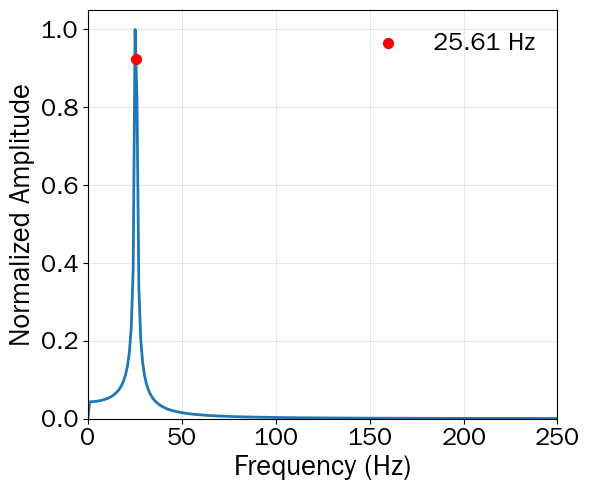

3DFIT: 方法频率=25.614435 Hz, 位移FFT峰值=25.176563 Hz
  图片已保存：3dfit_inline_spectrum_zdbiaochi.png


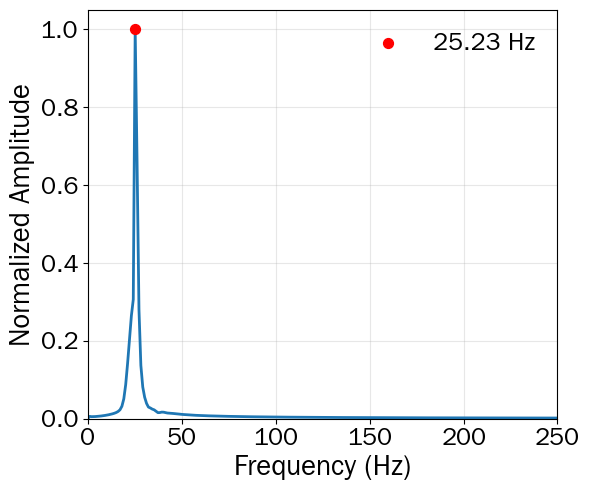

GPE: 方法频率=25.227043 Hz, 位移FFT峰值=25.227043 Hz
  图片已保存：gpe_inline_spectrum_zdbiaochi.png


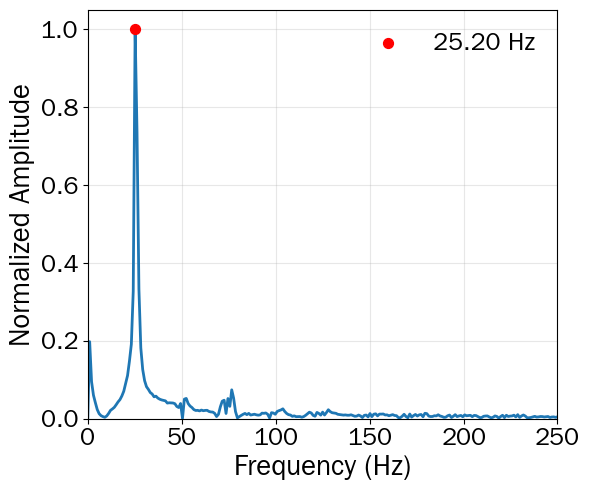

ECT: 方法频率=25.201613 Hz, 位移FFT峰值=25.201613 Hz
  图片已保存：ect_inline_spectrum_zdbiaochi.png


437

In [6]:
# 三种方法的独立实现：不调用 6.2 或 github 目录中的项目函数
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import minimize
from scipy.signal import butter, filtfilt, detrend, czt, find_peaks
from IPython.display import display

try:
    import finufft
except ImportError:
    finufft = None

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/zdbiaochi.hdf5").exists()), None)
if ROOT is None:
    raise FileNotFoundError("找不到 data/zdbiaochi.hdf5")

DATA_PATH = ROOT / "data/zdbiaochi.hdf5"
OUT_DIR = ROOT / "results_gangchi_inline"
OUT_DIR.mkdir(exist_ok=True)
ROI = (600, 700, 400, 600)       # xmin, xmax, ymin, ymax
TIME_RANGE = (0.0, 1.0)

# ---------- 读取并截取同一批原始事件 ----------
with h5py.File(DATA_PATH, "r") as handle:
    raw = handle["CD/events"][:]
x_all = raw["x"].astype(np.float64)
y_all = raw["y"].astype(np.float64)
t_all = raw["t"].astype(np.float64) * 1e-6
p_all = raw["p"].astype(np.float64)
del raw
xmin, xmax, ymin, ymax = ROI
tmin, tmax = TIME_RANGE
mask = ((x_all >= xmin) & (x_all <= xmax) &
        (y_all >= ymin) & (y_all <= ymax) &
        (t_all >= tmin) & (t_all <= tmax))
events = {"x": x_all[mask], "y": y_all[mask],
          "t": t_all[mask], "p": p_all[mask]}
del x_all, y_all, t_all, p_all, mask
if len(events["t"]) < 100:
    raise RuntimeError("ROI内事件数量不足")

def uniform_and_center(times, displacement):
    times = np.asarray(times, dtype=np.float64)
    displacement = np.asarray(displacement, dtype=np.float64)
    order = np.argsort(times)
    times, displacement = times[order], displacement[order]
    dt = float(np.median(np.diff(times)))
    if not np.allclose(np.diff(times), dt, rtol=1e-5, atol=1e-10):
        uniform_times = np.arange(times[0], times[-1] + 0.5 * dt, dt)
        displacement = np.interp(uniform_times, times, displacement)
        times = uniform_times
    return times - times[0], displacement - np.mean(displacement)

def fft_peak(times, displacement):
    dt = float(np.mean(np.diff(times)))
    frequencies = np.fft.rfftfreq(len(displacement), d=dt)
    magnitude = np.abs(np.fft.rfft(displacement - np.mean(displacement)))
    peak_index = int(np.argmax(magnitude[1:]) + 1)
    return float(frequencies[peak_index])

# =========================================================
# 方法一：ECT（1 ms质心、至少30个事件、sigma=1.0）
# =========================================================
dt_ect = 0.001
t0, t1 = events["t"].min(), events["t"].max()
n_bins = int((t1 - t0) // dt_ect)
ect_time_list, ect_center_list = [], []
for i in range(n_bins):
    ta, tb = t0 + i * dt_ect, t0 + (i + 1) * dt_ect
    in_bin = (events["t"] >= ta) & (events["t"] < tb)
    if np.count_nonzero(in_bin) >= 30:
        ect_time_list.append((ta + tb) / 2.0)
        ect_center_list.append(np.mean(events["y"][in_bin]))
ect_times_raw = np.asarray(ect_time_list)
ect_signal_raw = gaussian_filter1d(
    np.asarray(ect_center_list) - np.mean(ect_center_list), sigma=1.0)
ect_times, ect_signal = uniform_and_center(ect_times_raw, ect_signal_raw)
ect_frequency = fft_peak(ect_times, ect_signal)

# =========================================================
# 方法二：GPE（1 ms事件帧、复Gabor、20–40 Hz带通）
# =========================================================
frame_dt = 0.001
gx0, gx1 = int(events["x"].min()), int(events["x"].max())
gy0, gy1 = int(events["y"].min()), int(events["y"].max())
width, height = gx1 - gx0 + 1, gy1 - gy0 + 1
n_frames = int((t1 - t0) / frame_dt)
gpe_frames, gpe_frame_times = [], []
for k in range(n_frames):
    ta, tb = t0 + k * frame_dt, t0 + (k + 1) * frame_dt
    in_frame = (events["t"] >= ta) & (events["t"] < tb)
    if np.count_nonzero(in_frame) < 50:
        continue
    frame = np.zeros((height, width), dtype=np.float32)
    xs = (events["x"][in_frame] - gx0).astype(np.int32)
    ys = (events["y"][in_frame] - gy0).astype(np.int32)
    np.add.at(frame, (ys, xs), 1.0)
    gpe_frames.append(cv2.GaussianBlur(frame, (5, 5), 0))
    gpe_frame_times.append((ta + tb) / 2.0)
gpe_frames = np.asarray(gpe_frames)
gpe_frame_times = np.asarray(gpe_frame_times)

real_kernel = cv2.getGaborKernel(
    (31, 31), 4.0, np.pi / 2, 12.0, 0.5, 0, ktype=cv2.CV_32F)
imag_kernel = cv2.getGaborKernel(
    (31, 31), 4.0, np.pi / 2, 12.0, 0.5, np.pi / 2, ktype=cv2.CV_32F)
complex_responses = []
for frame in gpe_frames:
    real_response = cv2.filter2D(frame, cv2.CV_32F, real_kernel)
    imag_response = cv2.filter2D(frame, cv2.CV_32F, imag_kernel)
    complex_responses.append(real_response + 1j * imag_response)
complex_responses = np.asarray(complex_responses)
phase = np.unwrap(np.angle(complex_responses), axis=0)
response_amplitude = np.abs(complex_responses)
phase_increment = np.diff(phase, axis=0)
weighted_increment = (
    np.sum(phase_increment * response_amplitude[:-1], axis=(1, 2)) /
    (np.sum(response_amplitude[:-1], axis=(1, 2)) + 1e-6)
)
weighted_increment -= np.mean(weighted_increment)
pixel_increment = weighted_increment * 12.0 / (2.0 * np.pi)
sampling_rate = 1.0 / np.mean(np.diff(gpe_frame_times))
b, a = butter(4, [20.0 / (0.5 * sampling_rate),
                  40.0 / (0.5 * sampling_rate)], btype="band")
pixel_increment = filtfilt(b, a, pixel_increment)
gpe_signal_raw = gaussian_filter1d(detrend(np.cumsum(pixel_increment)), sigma=1.0)
gpe_times_raw = gpe_frame_times[1:]
gpe_times, gpe_signal = uniform_and_center(gpe_times_raw, gpe_signal_raw)
gpe_frequency = fft_peak(gpe_times, gpe_signal)
del gpe_frames, complex_responses, phase, response_amplitude, phase_increment

# =========================================================
# 方法三：3DFIT（PCA投影的Type-3 NUFFT初始化+隐式曲面拟合）
# 完整算法写在本单元内，不导入 github/methods/three_dfit。
# =========================================================
def nonuniform_transform(times, weights, frequencies):
    angular_frequencies = np.ascontiguousarray(2.0 * np.pi * frequencies)
    if finufft is not None:
        transform = finufft.nufft1d3(
            np.ascontiguousarray(times, dtype=np.float64),
            np.ascontiguousarray(weights, dtype=np.complex128),
            angular_frequencies, isign=-1, eps=1e-7)
        return transform, "finufft_type3"
    timestamp_step = 1e-6
    sample_index = np.rint(times / timestamp_step).astype(np.int64)
    sample_count = int(sample_index.max()) + 1
    gridded = (np.bincount(sample_index, weights=np.real(weights),
                           minlength=sample_count) +
               1j * np.bincount(sample_index, weights=np.imag(weights),
                                 minlength=sample_count))
    frequency_step = float(frequencies[1] - frequencies[0])
    transform = czt(
        gridded, m=len(frequencies),
        w=np.exp(-2j * np.pi * frequency_step * timestamp_step),
        a=np.exp(2j * np.pi * float(frequencies[0]) * timestamp_step))
    return transform, "scipy_czt_microsecond_grid"

def nufft_initialization(group_data):
    x, y, t = group_data["x"], group_data["y"], group_data["t"]
    xc, yc = x - np.mean(x), y - np.mean(y)
    covariance = np.cov(np.stack((xc, yc)))
    _, eigenvectors = np.linalg.eigh(covariance)
    normal = eigenvectors[:, 0]
    weights = normal[0] * xc + normal[1] * yc
    weights -= np.mean(weights)
    weight_scale = float(np.std(weights))
    weights = np.ascontiguousarray((weights / weight_scale).astype(np.complex128))
    elapsed = np.ascontiguousarray(t - np.min(t), dtype=np.float64)
    frequencies = np.arange(1.0, 500.0 + 0.05, 0.1)
    transform, backend = nonuniform_transform(elapsed, weights, frequencies)
    power = np.abs(transform)
    duration = float(np.ptp(elapsed))
    peak_distance = max(1, int(round(max(0.5, 1.0 / duration) / 0.1)))
    peak_indices, _ = find_peaks(power, distance=peak_distance)
    if len(peak_indices) == 0:
        peak_indices = np.array([int(np.argmax(power))])
    ordered = peak_indices[np.argsort(power[peak_indices])[::-1]]
    strongest = float(power[ordered[0]])
    strong = [int(i) for i in ordered if power[i] >= 0.5 * strongest]
    primary = float(np.min(frequencies[strong]))
    candidates = [primary]
    for index in ordered[:8]:
        f = float(frequencies[index])
        candidates.extend((f, f / 2.0, f / 3.0))
    unique = []
    for f in candidates:
        if 1.0 <= f <= 500.0 and not any(abs(f - old) < 0.05 for old in unique):
            unique.append(float(f))
    return {"frequency": primary, "candidates": unique, "normal": normal,
            "weight_scale": weight_scale, "frequencies": frequencies,
            "transform": transform, "backend": backend}

def fit_one_group(group_data):
    x_raw, y_raw, t_raw = group_data["x"], group_data["y"], group_data["t"]
    x, y, t = x_raw - np.mean(x_raw), y_raw - np.mean(y_raw), t_raw - np.min(t_raw)
    init = nufft_initialization(group_data)
    for initial_frequency in init["candidates"]:
        spectrum_index = int(np.argmin(np.abs(init["frequencies"] - initial_frequency)))
        coefficient = init["transform"][spectrum_index]
        initial_amplitude = max(
            2.0 * abs(coefficient) / len(t) * init["weight_scale"], 1e-6)
        initial_phase = float(
            (np.angle(coefficient) - 0.5 * np.pi + np.pi) % (2 * np.pi) - np.pi)
        p0 = [float(init["normal"][0]), float(init["normal"][1]),
              initial_amplitude, initial_frequency, initial_phase, 0.1, 0.0]

        def objective(parameters):
            A, B, C, frequency, phi, decay, D = parameters
            vibration = C * np.exp(-decay * t) * np.sin(
                2.0 * np.pi * frequency * t + phi)
            residual = A * x + B * y + vibration + D
            return np.mean(residual ** 2) + 1e6 * (np.hypot(A, B) - 1.0) ** 2

        half_window = max(0.5, 0.02 * initial_frequency)
        result = minimize(
            objective, p0, method="L-BFGS-B",
            bounds=[(-1, 1), (-1, 1), (0, None),
                    (max(1.0, initial_frequency - half_window),
                     min(500.0, initial_frequency + half_window)),
                    (-np.pi, np.pi), (0, 10), (None, None)])
        if not result.success or not np.all(np.isfinite(result.x)):
            continue
        A, B, C, frequency, phi, decay, D = result.x
        normal_norm = float(np.hypot(A, B))
        if normal_norm <= 1e-9:
            continue
        model_residual = (A * x + B * y +
                          C * np.exp(-decay * t) * np.sin(2*np.pi*frequency*t + phi) + D)
        static_residual = A * x + B * y + D
        model_mse = float(np.mean(model_residual ** 2))
        static_mse = float(np.mean(static_residual ** 2))
        improvement = ((static_mse - model_mse) / static_mse
                       if static_mse > 1e-12 else 0.0)
        amplitude = float(abs(C) / normal_norm)
        if amplitude < 1e-3 or improvement < 1e-6 or frequency <= 1.05 or frequency >= 499.95:
            continue
        parameters = result.x.copy()
        parameters[[0, 1, 2, 6]] /= normal_norm
        return {"params": parameters, "improvement": improvement,
                "nufft_frequency": init["frequency"], "backend": init["backend"]}
    return None

# 与github版本一致：按x方向分组；当前ROI宽度小于800 px，形成一个有效组。
group_size, min_events = 800, 100
bounds = np.arange(events["x"].min(), events["x"].max() + group_size, group_size)
fitted_groups = []
for group_id in range(len(bounds) - 1):
    group_mask = ((events["x"] >= bounds[group_id]) &
                  (events["x"] < bounds[group_id + 1]))
    if np.count_nonzero(group_mask) < min_events:
        continue
    fitted = fit_one_group({key: value[group_mask] for key, value in events.items()})
    if fitted is not None:
        fitted_groups.append(fitted)
if not fitted_groups:
    raise RuntimeError("3DFIT连续隐式曲面拟合失败")

fit_frequency = float(np.median([g["params"][3] for g in fitted_groups]))
fit_amplitude = float(np.median([
    abs(g["params"][2]) / np.hypot(g["params"][0], g["params"][1])
    for g in fitted_groups]))
fit_decay = float(np.median([g["params"][5] for g in fitted_groups]))
duration = float(np.ptp(events["t"]))
sample_count = max(2, int(np.ceil(duration * max(2000, 4 * fit_frequency))))
elapsed = np.arange(sample_count) * duration / sample_count
fit_signal_raw = (fit_amplitude * np.exp(-fit_decay * elapsed) *
                  np.sin(2.0 * np.pi * fit_frequency * elapsed))
fit_times, fit_signal = uniform_and_center(elapsed + events["t"].min(), fit_signal_raw)

method_results = {
    "3DFIT": {"times": fit_times, "signal": fit_signal,
               "frequency_hz": fit_frequency},
    "GPE": {"times": gpe_times, "signal": gpe_signal,
            "frequency_hz": gpe_frequency},
    "ECT": {"times": ect_times, "signal": ect_signal,
            "frequency_hz": ect_frequency},
}

# ---------- 第二个代码块：三种方法的归一化单边频谱 ----------
spectrum_summary = {}
for name in ("3DFIT", "GPE", "ECT"):
    result = method_results[name]
    times = np.asarray(result["times"])
    displacement = np.asarray(result["signal"]) - np.mean(result["signal"])
    dt = float(np.mean(np.diff(times)))
    frequencies = np.fft.rfftfreq(len(displacement), d=dt)
    magnitude = np.abs(np.fft.rfft(displacement))
    normalized = magnitude / (np.max(magnitude) + 1e-12)
    peak_index = int(np.argmax(normalized[1:]) + 1)
    fft_peak_hz = float(frequencies[peak_index])
    method_frequency_hz = float(result["frequency_hz"])
    marker_frequency_hz = method_frequency_hz if name == "3DFIT" else fft_peak_hz
    marker_amplitude = float(np.interp(marker_frequency_hz, frequencies, normalized))
    spectrum_summary[name] = {
        "method_frequency_hz": method_frequency_hz,
        "fft_peak_hz": fft_peak_hz,
        "samples": int(len(displacement)), "dt_s": dt,
    }
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(frequencies, normalized, lw=2, color="tab:blue")
    ax.scatter(marker_frequency_hz, marker_amplitude, color="red", s=50,
               zorder=3, label=f"{marker_frequency_hz:.2f} Hz")
    ax.set_xlabel("Frequency (Hz)", fontsize=20)
    ax.set_ylabel("Normalized Amplitude", fontsize=20)
    ax.set_xlim(0, 250)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="both", labelsize=18)
    ax.legend(frameon=False, fontsize=18, loc="upper right")
    fig.tight_layout()
    image_path = OUT_DIR / f"{name.lower()}_inline_spectrum_zdbiaochi.png"
    fig.savefig(image_path, dpi=300, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print(f"{name}: 方法频率={method_frequency_hz:.6f} Hz, "
          f"位移FFT峰值={fft_peak_hz:.6f} Hz")
    print(f"  图片已保存：{image_path.name}")

(OUT_DIR / "inline_spectrum_summary.json").write_text(
    json.dumps(spectrum_summary, ensure_ascii=False, indent=2), encoding="utf-8")
